# Introduction

The objective of this notebook is to walk you through statespace models in building energy efficiency applications. 

You will learn the following concepts:
* What is a statespace model
* How to construct a deterministic statespace model
* How to construct a stochastic state space model
* How to construct the model matrices and to discritize them
* How to use kalman filter steps to construct the likelihood function
* How this model is sensitive to various different intialization and parameters setup

The notebook will guide you through visualizing the indiviual steps if the kalman filter to allow you to have a good deep understanding of what is really happening on the step level.

A simple 2R2C case study will be used in this notebook. 

In [89]:
import pandas as pd
import numpy as np
from scipy.linalg import expm, inv
from matplotlib import pyplot as plt

# Data Loading
The data we will be exploring in this example is a very simple data set, it has no gains, the indoor temperature varies due to the external temperature variation

The data frequency is hourly. So 

In [90]:
data = pd.read_csv("data.csv", delimiter=";").set_index("Step")
data.drop(data.index[-1], axis=0, inplace=True)
sT = 3600 * 24
data.index = data.index*3600 / sT  # Change time scale to days

# 2. State space model without process noise
The following is a statespace model formulation for a deterministic model

$$x = A x_t+Bu_t$$
$$y_t=Cx_t$$

where:

* $x_t$: is a p-dimensional vector of all states calculated by the model (in our context it is the temperatures calculated by the model for all nodes (indoor, and wall ...)). For example in a 1R1C model the indoor temperature is the only model output, so in this case p=1. In a 2R2C model we compute the indoor and the envelope temperature, thus p=2 etc.
  
* $y_t$ is a q-dimensional vector of output temperatures that will be compared to measurements (typically q = 1 and y(t) is the indoor temperature) since this is the observable measurable quantity, the walls temperatures are normally hidden states that we do not measure (observe)
  
* $u_t$ is an r-dimensional vector of boundary conditions (e.g. heat input, solar radiation, outdoor temperature, ...)

## 2.1 2R2C deterministic model

In a 2R2C model we have one node representing the envelope temperature and another node representing the zone temperature.

$$ A = \begin{bmatrix}
    -1/C_1R_1 - 1/C_1R_2 & 1/C_1R_2 \\
    1/C_2R_2  & -1/C_2R_2
\end{bmatrix} $$

$$ B = \begin{bmatrix}
    1/C_1R_1  & 0 \\
    0  & 1/C_2 
\end{bmatrix} $$

$$ C = \begin{bmatrix}
    0  & 1 
\end{bmatrix} $$

In the following cell you have to build a function that constructs these matrices for 2R2C statespace model


In [91]:
def build_continuous_matrices(R1, R2, C1, C2):
    A = np.array([
        [-(1/(C1*R1) + 1/(C1*R2)),  1/(C1*R2)],
        [ 1/(C2*R2),               -1/(C2*R2)]
    ])

    B = np.array([
        [1/(C1*R1),  0],  # T_ext, q
        [0,           1/C2]
    ])
    
    C = np.array([[0, 1]])  # Output: indoor air temp
    return A, B, C

# 2.2 Discretisation of the contineous matrices

To work with state-space models on a digital computer or controller, we discretize them so we can compute the states at each discrete time step instead of continuously.

The statespace model in discrete formulation becomes

$$x_{[t+1]}=A_d​x_t + B​_du_t$$

where:

$$
A_d = e^{A T}
$$

$$
B_d​=A^{-1}​(A_d​−I)B​​
$$

In the following cell implement a function that transforms the contineuos contineuos statespace model into discrete

In [92]:
def discretize(time_step: float, Ac: np.ndarray, Bc: np.ndarray):
    Ad = expm(Ac * time_step)
    Bd = inv(Ac) @ (Ad - np.eye(Ac.shape[0])) @ Bc
    return Ad, Bd

# 2.3 Forward simulation
To do forward simulation you will have to construct the model matrices and discretise them and then solve the following equation sequentially feeding the results of each time step to the next time step:

$$x_{[t+1]}=A_d​x_t + B​_du_t$$

In the following block you will implement this sequential prediction of the states through the following steps:
 1. Initialize the model essential parameters and states
 2. Get necessary inputs from the data to feed to your model
 3. Set up the discretised matrices
 4. Run the forward predictions

In [93]:
## Get necessary inputs from the data
time = data.index
T_ext = np.array(data['Text'])
q = np.array(data['Qheat'])
time_step = time[1] - time[0]  # time step in days

In [94]:
## Define system parameters
R1 = 0.001  # K/W
R2 = 0.001    # K/W
C1 = 1e7 / sT    # W.day/K
C2 =  1e6 / sT   # W.day/K
T_in_initial =  3 # initial indoor temperature (you can get it from the data)
T_w_initial =  2 # initial wall temperature (assumption you do normally this can be identified along with the other parameters)

In [95]:
## Build system matrices
Ac, Bc, C = build_continuous_matrices(R1, R2, C1, C2)
Ad, Bd = discretize(time_step, Ac, Bc)

In [96]:
## Implement the forward simulation
# Initialisation
uk = np.vstack([T_ext, q])
xk = np.zeros((Ad.shape[0], uk.shape[1]))  # initial state
xk[:, 0] = np.array([T_w_initial, T_in_initial])  # initial external temp (pay attention to the order should be consistent with the A and C matrix)

# Initialize as lists to preserve dimensions when appending
x_prediction = []
x = np.array([xk[:, 0]]).T
x_prediction.append(x)
for i in range(1, len(time)):
    uk = np.vstack([T_ext[i], q[i]])
    # Prediction step
    x = Ad @ x + Bd @ uk
    x_prediction.append(x)
x_prediction = np.hstack(x_prediction)

# 2.4 Encapsulating everything in a function
Now after validating all the steps, it would be helpful to combine everything in a function which will allow to prrovide inputs and initialisations and to get the model prediction. 

This is necessary for the following step where you will need to analyse the model performance and apply some sensitivity analysis

In [97]:
def forward_simulation(R1, R2, C1, C2, T_w_initial, T_in_initial, T_ext, q, time_step):
    ## Build system matrices
    Ac, Bc, C = build_continuous_matrices(R1, R2, C1, C2)
    Ad, Bd = discretize(time_step, Ac, Bc)

    ## Implement the forward simulation
    # Initialisation
    uk = np.vstack([T_ext, q])
    xk = np.zeros((Ad.shape[0], uk.shape[1]))  # initial state
    xk[:, 0] = np.array([T_w_initial, T_in_initial])  # initial external temp (pay attention to the order should be consistent with the A and C matrix)

    # Initialize as lists to preserve dimensions when appending
    x_prediction = []
    x = np.array([xk[:, 0]]).T
    x_prediction.append(x)
    for i in range(1, len(time)):
        uk = np.vstack([T_ext[i], q[i]])
        # Prediction step
        x = Ad @ x + Bd @ uk
        x_prediction.append(x)
    x_prediction = np.hstack(x_prediction)
    return x_prediction

## Define system parameters
R1 = 0.001  # K/W
R2 = 0.001    # K/W
C1 = 1e7 / sT    # W.day/K
C2 =  1e6 / sT   # W.day/K
T_in_initial =  3 # initial indoor temperature (you can get it from the data)
T_w_initial =  2 # initial wall temperature (assumption you do normally this can be identified along with the other parameters)

x_prediction = forward_simulation(R1, R2, C1, C2, T_w_initial, T_in_initial, T_ext, q, time_step)


# 2.4 Visualization and anlaysis of results
After performing the forward simulation you can have a look on the predicted values over a certain time horizon you specify.

This will serve two objectives:
1. Validation of the implementation / detection of un logic performance
2. Analyse and better understand the behaviour of the RC model by tuning its parameter (so you can rerun the forward simulation using various R and C and various other initialization) 

**Questions**
1. What happens when you set R high ? can you have a physical explanation to that ?

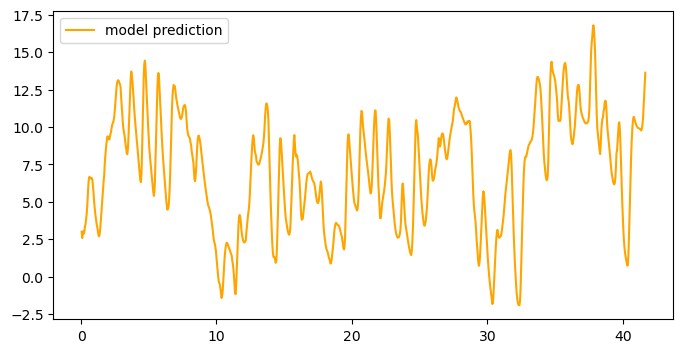

In [98]:
step = [0, 1000]
specified_horizon = time[step[0]:step[1]]
specified_horizon_preds = x_prediction[1,step[0]:step[1]] # be careful with the indexing here (should index the indoor temperature)
specified_horizon_Text = T_ext[step[0]:step[1]]
# Plot results
fig, ax = plt.subplots(figsize=(8,4))
# ax.plot(specified_horizon, specified_horizon_Text, color='blue', label='T_ext (measured)')
ax.plot(specified_horizon, specified_horizon_preds, color='orange', label='model prediction')
ax.legend()

# 3. State space model with process noise
The following is a statespace model formulation for a **stochastic** model

$$x = A x_t+Bu_t+w_t$$
$$y_t=Cx_t+v_t$$

where:
$$w_t∼N(0,Q_c)$$
$$v_t∼N(0,R_c)$$

* $w_t$ is the process noise
  
* $v_t$ is the measurement noise

* $Q_c$ is a pxp covariance matrix describing the uncertainty of the states

* $R_c$ is qxq matrix describing the uncertainty of the measurements

## 3.1 2R2C stochastic model

The matrices of this model are similar to the previous ones except that now we have two additional covariance matrices $Q_c$ and $R_c$.

$$ Q_c = \begin{bmatrix}
    {q_1}^2  & 0 \\
    0 &  {q_2}^2
\end{bmatrix} $$

$$ R_c = \begin{bmatrix}
    {r}^2
\end{bmatrix} $$

* $q_1$ is the model uncertainty in predicting the first state ($T_w$ in this example)
* $q_2$ is the model uncertainty in predicting the second state ($T_{air}$ in this example)
* $r$ is the measurements uncertainty

All of these three values are standard deviations.

In the following cell you have to build a function that constructs these matrices for 2R2C statespace model


In [99]:
## Build system matrices with noise covariances (same as before but we add two additional covaraince matrices))
def build_continuous_matrices_stochastic(R1, R2, C1, C2, qi, qe, r):
    A = np.array([
        [-(1/(C1*R1) + 1/(C1*R2)),  1/(C1*R2)],
        [ 1/(C2*R2),               -1/(C2*R2)]
    ])

    B = np.array([
        [1/(C1*R1),  0],  # T_ext, q
        [0,           1/C2]
    ])
    
    C = np.array([[0, 1]])  # Output: indoor air temp

    # System and measurement error covariance matrices
    Qc = np.diag([qe**2, qi**2])
    Rc = np.array([[r ** 2]])
    return A, B, C, Qc, Rc

# 3.2 Discretisation of the contineous matrices

The stochastic statespace model in discrete formulation becomes

$$x_{[t+1]}=A_d​x_t + B​_du_t + w_t$$
$$y_{t+1}=Cx_{t+1}+v_{t+1}$$

where:
$$w_t∼N(0,Q_d)$$
$$v_t∼N(0,R_d)$$

$$
R_d = R_c / \Delta t
$$

$$
\
Q_d =  \int_{0}^{\Delta t} e^{A_c \Delta t}Q_c e^{A_c^T \Delta t} \,dx
\
$$

$A_d$ and $B_d$ are computed in the same way as before

**Note**: 
This integral in computing $Q_d$ is not trivial to compute directly for matrices $A_c$ of arbitrary size. Van Loan came up with a matrix exponential trick to compute $Q_d$ exactly. The idea is to turn the integral into a larger matrix exponential problem:

1. Construct a block matrix:

$$ M = \begin{bmatrix}
    -A_c  & Q_c \\
    0 &  A_c^T
\end{bmatrix} \times \Delta t $$

2. Compute the matrix exponential:

$$ e^M = \begin{bmatrix}
    \phi_{11}  & \phi_{12} \\
    0 &  \phi_{22}
\end{bmatrix} $$

3. $Q_d$ can then be exactly computed as follows:

$$
Q_d = \phi_{22}^T \phi_{12}
$$   

In the following cell implement a function that transforms the contineuos contineuos statespace model into discrete

In [100]:
def discretize_stochastic(time_step: float, Ac: np.ndarray, Bc: np.ndarray, Qc=None, Rc=None):
    Ad = expm(Ac * time_step)
    Bd = inv(Ac) @ (Ad - np.eye(Ac.shape[0])) @ Bc

    if Qc is None or Rc is None:
        return Ad, Bd
    else: 
        n = Ac.shape[0]
        foo = expm(np.block([[-Ac, Qc], [np.zeros(np.shape(Ac)), Ac.T]]) * time_step)
        Qd = np.dot(foo[n:2 * n, n:2 * n].T, foo[0:n, n:2 * n])
        # Measurement error covariance matrix (discrete)
        Rd = Rc / time_step
        return Ad, Bd, Qd, Rd

# 3.3 Forward simulation 
To do forward simulation you will have to construct the model matrices and discretise them and then solve the following equation sequentially feeding the results of each time step to the next time step (just like before).

However now since the model is stochastic, at each time step there will be more than one probable prediction of the states. Accodingly at each time step we will propagate the whole distribution of states. Since we assume gaussian distributions, the states at each step are gaussian distributions with mean and covariance. 

In the forward simulation, we can sequentially use the states distribution at the current time step to predict the state mean and covariance distribution at the next time step. The states covariaces at each time step will be denoted as $P$

$$x_{t+1}=A_d​x_t + B​_du_t$$
$$P_{t+1}=A_d​P_tA_d^T + Q_d$$

In the following block you will implement this sequential prediction of the states through the following steps:
 1. Initialize the model essential parameters and states (in addition to previously you will also have to set values for the states uncertainties) and for the initial covariance of the states.
   
 2. Get necessary inputs from the data to feed to your model
 3. Set up the discretised matrices
 4. Run the forward predictions

In [101]:
def forward_simulation_stochastic(R1, R2, C1, C2, qi, qe, r, T_w_initial, T_in_initial, T_ext, q, time_step):
    ## Build system matrices
    Ac, Bc, C, Qc, Rc = build_continuous_matrices_stochastic(R1, R2, C1, C2, qi, qe, r)
    Ad, Bd, Qd, Rd = discretize_stochastic(time_step, Ac, Bc, Qc, Rc)

    ## Implement the forward simulation
    # Initialisation
    uk = np.vstack([T_ext, q])
    xk = np.zeros((Ad.shape[0], uk.shape[1]))  # initial state
    P = np.eye(2)  # initial state covariance
    xk[:, 0] = np.array([T_w_initial, T_in_initial])  # initial external temp (pay attention to the order should be consistent with the A and C matrix)

    # Initialize as lists to preserve dimensions when appending
    x_prediction = []
    P_prediction = []
    x = np.array([xk[:, 0]]).T
    x_prediction.append(x)
    P_prediction.append(P)
    for i in range(1, len(time)):
        uk = np.vstack([T_ext[i], q[i]])
        # Prediction step
        x = Ad @ x + Bd @ uk
        P = Ad @ P @ Ad.T + Qd
        x_prediction.append(x)
        P_prediction.append(P)
    x_prediction = np.hstack(x_prediction)
    P_prediction = np.array(P_prediction).flatten()[3::4]
    return x_prediction, P_prediction

## Define system parameters
R1 = 0.001  # K/W
R2 = 0.001    # K/W
C1 = 1e7 / sT    # W.day/K
C2 =  1e6 / sT   # W.day/K
qi = 1e-3 * sT**0.5  # process noise for internal temp
qe = 1e-3 * sT**0.5  # process noise for wall temp
r = 1e-2              # measurement noise for internal temp
T_in_initial =  3 # initial indoor temperature (you can get it from the data)
T_w_initial =  2 # initial wall temperature (assumption you do normally this can be identified along with the other parameters)

x_prediction, P_prediction = forward_simulation_stochastic(R1, R2, C1, C2, qi, qe, r, T_w_initial, T_in_initial, T_ext, q, time_step)

# 3.4 Visualization and anlaysis of results
After performing the forward simulation you can have a look on the predicted values over a certain time horizon you specify.

This will serve two objectives:
1. Validation of the implementation / detection of un logic performance
2. Analyse and better understand the behaviour of the RC model by tuning its parameter (so you can rerun the forward simulation using various R and C and various other initialization) 

**Questions**
1. How does the model uncertainties evolve? Can you have an explanation to that?
2. when you set unrealistic parameters what happens to the model uncertainty? Can you explain why?

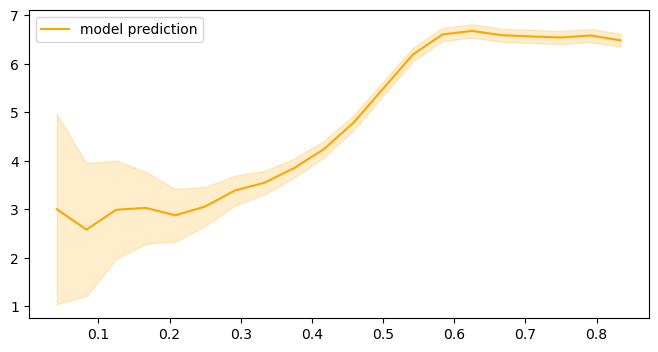

In [103]:
step = [0, 20]
specified_horizon = time[step[0]:step[1]]
specified_horizon_preds = x_prediction[1,step[0]:step[1]] # be careful with the indexing here (should index the indoor temperature)
specified_horizon_vars = P_prediction[step[0]:step[1]]
specified_horizon_Text = T_ext[step[0]:step[1]]
# Plot results
fig, ax = plt.subplots(figsize=(8,4))
# ax.plot(specified_horizon, specified_horizon_Text, color='blue', label='T_ext (measured)')
ax.plot(specified_horizon, specified_horizon_preds, color='orange', label='model prediction')
ax.fill_between(specified_horizon, specified_horizon_preds-1.96*np.sqrt(specified_horizon_vars), specified_horizon_preds+1.96*np.sqrt(specified_horizon_vars), color='orange', alpha=0.2)
ax.legend()

## 4. Statespace model with process noise and kalman updates

In the previous sections we worked with stochastic statespace models in forecasting mode, which means that the observed states (measurements) are not used during the forward simulation to update our belief about the states values. To achieve this we can add kalman steps to the forward simulation function.

An additional advantage of kalman filter is that it transforms an impossible high-dimensional integral over all possible hidden state paths into a sequence of simple Gaussian updates; these updates simultaneously estimate the hidden state and provide the predictive distributions needed to compute the likelihood.

The 2R2C model formulation with kalman filter is same as the one illustrated previously. Essentially there is no difference in the matrices construction (contineous and discrete). 

The forward simulation with kalman filter consists of 4 steps:

1. Prediction (which is exactly the forward simulation illustrated previously)
$$x_{t+1}^{prior}=A_d​x_t^{post} + B​_du_t$$
$$P_{t+1}^{prior}=A_d​P_t^{post}A_d^T + Q_d$$

2. Innovation (measurement arrives --> compute prediction error and its covariance). Note that this step computes the likelihood distribution parameters at step $t+1$.
$$\varepsilon_{t+1}=y_{t+1} - Cx_{t+1}^{prior}$$
$$ \S_{t+1} = CP_{t+1}^{prior}C^T + R $$


3. Kalman gain (a coefficient telling how much I trust the measurement vs. model prediction)
$$K_{t+1} = P_{t+1}^{prior}C^TS_{t+1}^{-1}$$

4. Update (posterior where we update the state estimates mean and covariance using the measurements)
$$x_{t+1}^{post} = x_{t+1}^{prior} + K_{t+1}\varepsilon_{t+1}$$
$$P_{t+1}^{post} = (I - K_{t+1}C)P_{t+1}^{prior}$$

5. Likelihood computation via the constructed distributions at step 2
$$ \frac{1}{\sqrt{2\pi|S_{t+1}|}} exp(-\frac{1}{2}\varepsilon_{t+1}^TS_{t+1}^{-1}\varepsilon_{t+1}) $$

At step 5 it is better to compute the loglikelihood instead of the likelihood to avoid numerical problems so you can use this formula instead
$$ -\frac{1}{2} log(2\pi) -\frac{1}{2} log|S_{t+1}| - \frac{1}{2}\varepsilon_{t+1}^TS_{t+1}^{-1}\varepsilon_{t+1} $$

So the steps from 1 to 5 should be repeated over all timesteps. At the end the loglikelihood is simply the sum of the likelihoods computed at each timestep

In the following cell, you should implement kalman filtering and compute the loglikelihood of the parameters you proposed

In [104]:
def forward_simulation_stochastic(R1, R2, C1, C2, qi, qe, r, T_w_initial, T_in_initial, Tint, T_ext, q, time_step):
    ## Build system matrices
    Ac, Bc, C, Qc, Rc = build_continuous_matrices_stochastic(R1, R2, C1, C2, qi, qe, r)
    Ad, Bd, Qd, Rd = discretize_stochastic(time_step, Ac, Bc, Qc, Rc)

    ## Implement the forward simulation
    # Initialisation
    uk = np.vstack([T_ext, q])
    xk = np.zeros((Ad.shape[0], uk.shape[1]))  # initial state
    xk[:, 0] = np.array([T_w_initial, T_in_initial])  # initial external temp (pay attention to the order should be consistent with the A and C matrix)

    # Initialize as lists to preserve dimensions when appending
    x_prior_handler = []
    P_prior_handler = []
    x_posterior_handler = []
    P_posterior_handler = []
    loglike_handler = []
    x_post = np.array([xk[:, 0]]).T
    P_post = np.eye(2)  # initial state covariance
    
    x_prior_handler.append(x_post) # Prior at time 0 is same as posterior at time 0 since intialization step
    P_prior_handler.append(P_post)
    x_posterior_handler.append(x_post)
    P_posterior_handler.append(P_post)

    likelihoods_handler = [1] # Initialize with dummy value (first value is initialisation and no likelihood is associated with)
    loglikelihoods_handler = [1]
    sigmas_handler = [1]

    for i in range(1, len(time)):
        uk = np.vstack([T_ext[i], q[i]])
        
        # Step1 : Prediction step
        x_prior = Ad @ x_post + Bd @ uk
        P_prior = Ad @ P_post @ Ad.T + Qd  # Use x_post and P_post of previous timestep

        # Step2 : Innovation
        y = np.array([[Tint[i]]])
        epsilun = y - (C @ x_prior)
        Sigma = C @ P_prior @ C.T + Rd  # innovation covariance
        Kt = P_prior @ C.T @ inv(Sigma)  # Kalman gain

        # Step3 : Likelihood computation
        likelihood = (1 / np.sqrt(2*np.pi*Sigma[0,0])) * np.exp(-(epsilun[0,0])**2 / (2 * Sigma[0,0]))
        loglikelihood = -0.5 * np.log(2 * np.pi) - 0.5 * np.log(Sigma[0,0]) - 0.5 * (epsilun[0,0] ** 2 / Sigma[0,0])

        # Step4 : Update
        x_post = x_prior + Kt @ epsilun
        P_post = (np.eye(2) - Kt @ C) @ P_prior  # updated estimate covariance

        # storing data
        x_prior_handler.append(x_prior)
        P_prior_handler.append(P_prior)
        x_posterior_handler.append(x_post)
        P_posterior_handler.append(P_post)
        likelihoods_handler.append(likelihood)
        loglikelihoods_handler.append(loglikelihood)
        sigmas_handler.append(Sigma[0,0])

    x_prior_handler = np.hstack(x_prior_handler)
    P_prior_handler = np.array(P_prior_handler).flatten()[3::4]
    x_posterior_handler = np.hstack(x_posterior_handler)
    P_posterior_handler = np.array(P_posterior_handler).flatten()[3::4]
    likelihoods_handler = np.array(likelihoods_handler)
    loglikelihoods_handler = np.array(loglikelihoods_handler)
    sigmas_handler = np.array(sigmas_handler)
    return x_prior_handler, P_prior_handler, x_posterior_handler, P_posterior_handler, likelihoods_handler, loglikelihoods_handler, sigmas_handler

## Define system parameters
R1 = 0.001  # K/W
R2 = 0.001    # K/W
C1 = 1e7 / sT    # W.day/K
C2 =  1e6 / sT   # W.day/K
qi = 1e-3 * sT**0.5  # process noise for internal temp
qe = 1e-3 * sT**0.5  # process noise for wall temp
r = 1e-2              # measurement noise for internal temp
T_in_initial =  3 # initial indoor temperature (you can get it from the data)
T_w_initial =  2 # initial wall temperature (assumption you do normally this can be identified along with the other parameters)
Tint = np.array(data['Tint'])

x_prior, P_prior, x_posterior, P_posterior, likelihoods, loglikelihoods, sigmas = forward_simulation_stochastic(R1, R2, C1, C2, qi, qe, r, T_w_initial, T_in_initial, Tint, T_ext, q, time_step)

# 4.1 Visualization and anlaysis of results
After performing the forward simulation with kalman updates you can have a look on the model prior state distributions and the posterior state distributions at each time step over a certain time horizon you specify.

This will serve two objectives:
1. Validation of the implementation / detection of un logic performance
2. Analyse and better understand the behaviour of kalman filter by tuning its parameter (so you can rerun the forward simulation using various model and measurement uncertainties Q&R and analyse the filter performance to gain better understanding on what is happening)

Main graph to plot is a graph that shows:
* External temperature
* Measured internal temperature
* Internal temperature prior estimates (with the variance bound under 95% confidence)
* Internal temperature posterior estimates (with the variance bound under 95% confidence)

**Questions**
1. What happens when you vary the values of Q and R? how do you explain that?

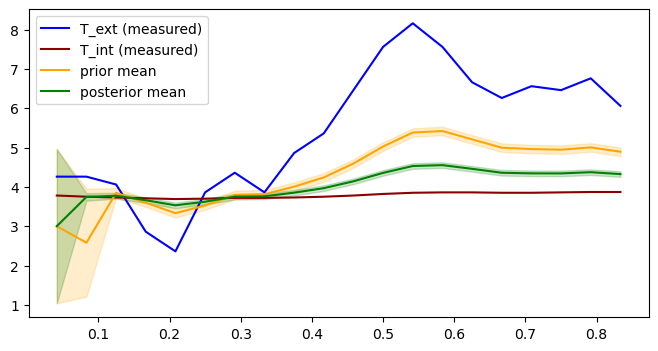

In [105]:
step = [0, 20]
specified_horizon = time[step[0]:step[1]]
specified_horizon_prior_mean = x_prior[1,step[0]:step[1]] # be careful with the indexing here (should index the indoor temperature)
specified_horizon_prior_vars = P_prior[step[0]:step[1]]
specified_horizon_post_mean = x_posterior[1,step[0]:step[1]] # be careful with the indexing here (should index the indoor temperature)
specified_horizon_post_vars = P_posterior[step[0]:step[1]]
specified_horizon_Text = T_ext[step[0]:step[1]]
specified_horizon_Tint = Tint[step[0]:step[1]]

# Plot results
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(specified_horizon, specified_horizon_Text, color='blue', label='T_ext (measured)')
ax.plot(specified_horizon, specified_horizon_Tint, color='darkred', label='T_int (measured)')
ax.plot(specified_horizon, specified_horizon_prior_mean, color='orange', label='prior mean')
ax.fill_between(specified_horizon, specified_horizon_prior_mean-1.96*np.sqrt(specified_horizon_prior_vars), specified_horizon_prior_mean+1.96*np.sqrt(specified_horizon_prior_vars), color='orange', alpha=0.2)
ax.plot(specified_horizon, specified_horizon_post_mean, color='green', label='posterior mean')
ax.fill_between(specified_horizon, specified_horizon_post_mean-1.96*np.sqrt(specified_horizon_post_vars), specified_horizon_post_mean+1.96*np.sqrt(specified_horizon_post_vars), color='green', alpha=0.2)
ax.legend()

# 4.1.1 Kalman filter steps visualization
Now we will try to visualize the steps of kalman filter for 5 steps. You will have to replicate the graph that you see hereunder. 

Things to visalize on each time step:
* Prior distribution of the indoor temperature
* Posterior  distribution of the indoor temperature
* Measured indoor temperature distribution
* Likelihood distribution

It is better to draw the likelihood distributions at each step on a seperate graph

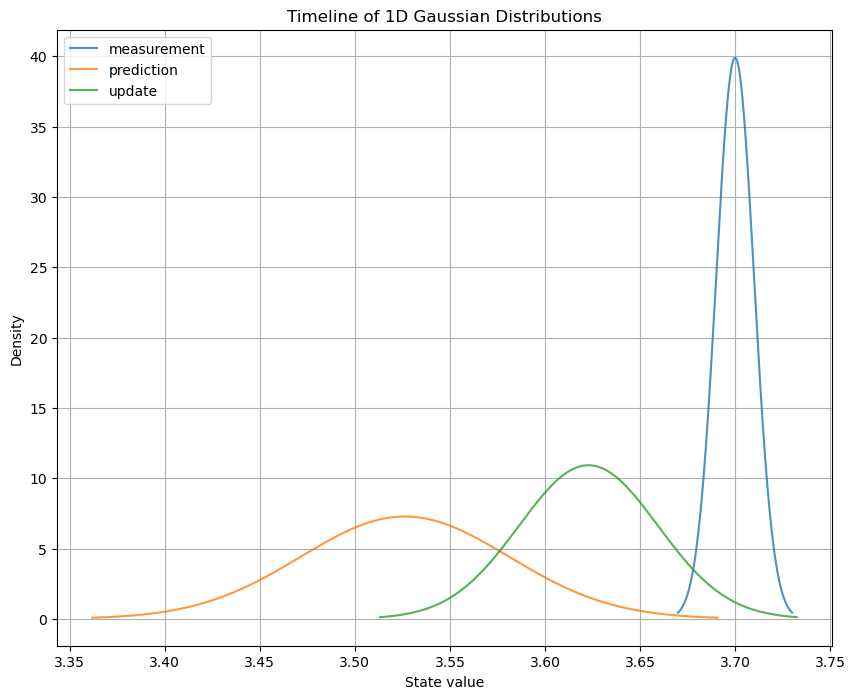

In [106]:
## visualization of a step priors, measurement and posteriors
step = 5

step_measured_mean = Tint[step]
step_measured_var = r ** 2
xm = np.linspace(step_measured_mean - 3 * step_measured_var**0.5, step_measured_mean + 3 * step_measured_var**0.5, 500)
step_pdf_meas = (1 / np.sqrt(2*np.pi*step_measured_var)) * np.exp(-(xm - step_measured_mean)**2 / (2 * step_measured_var))

step_prior_mean = x_prior[1,step]
step_prior_var = P_prior[step]
x_grid_prior = np.linspace(step_prior_mean - 3 * step_prior_var**0.5, step_prior_mean + 3 * step_prior_var**0.5, 500)
step_pdf_prior = (1 / np.sqrt(2*np.pi*step_prior_var)) * np.exp(-(x_grid_prior - step_prior_mean)**2 / (2 * step_prior_var))

step_post_mean = x_posterior[1,step]
update_var = P_posterior[step]
x_grid_post = np.linspace(step_post_mean - 3 * update_var**0.5, step_post_mean + 3 * update_var**0.5, 500)
step_pdf_post  = (1 / np.sqrt(2*np.pi*update_var))  * np.exp(-(x_grid_post - step_post_mean)**2  / (2 * update_var))

plt.figure(figsize=(10, 8))
plt.plot(xm, step_pdf_meas, label="measurement", alpha=0.8)
plt.plot(x_grid_prior, step_pdf_prior, label="prediction", alpha=0.8)
plt.plot(x_grid_post, step_pdf_post, label="update", alpha=0.8)
plt.xlabel("State value")
plt.ylabel("Density")
plt.title("Timeline of 1D Gaussian Distributions")
plt.legend()
plt.grid(True)
plt.show()

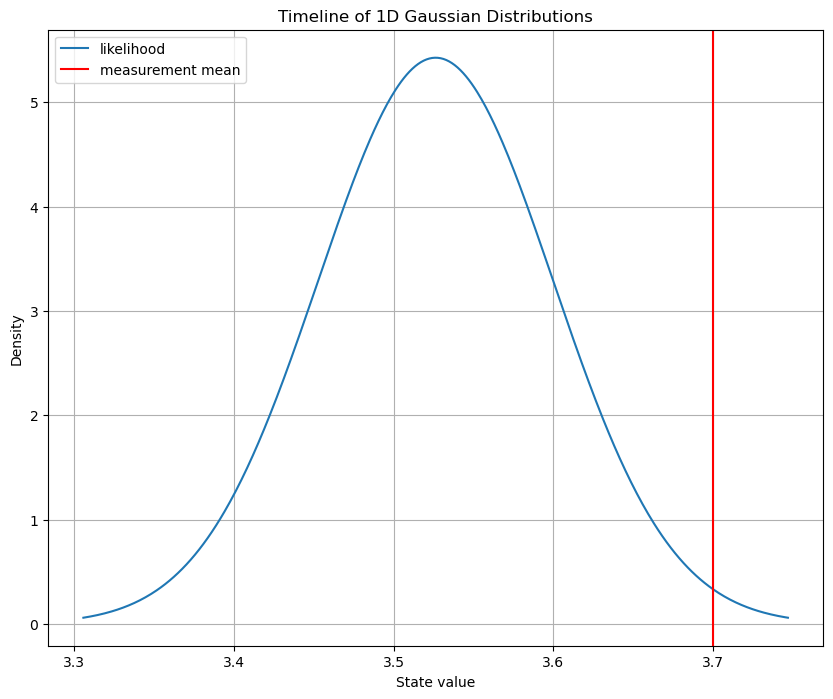

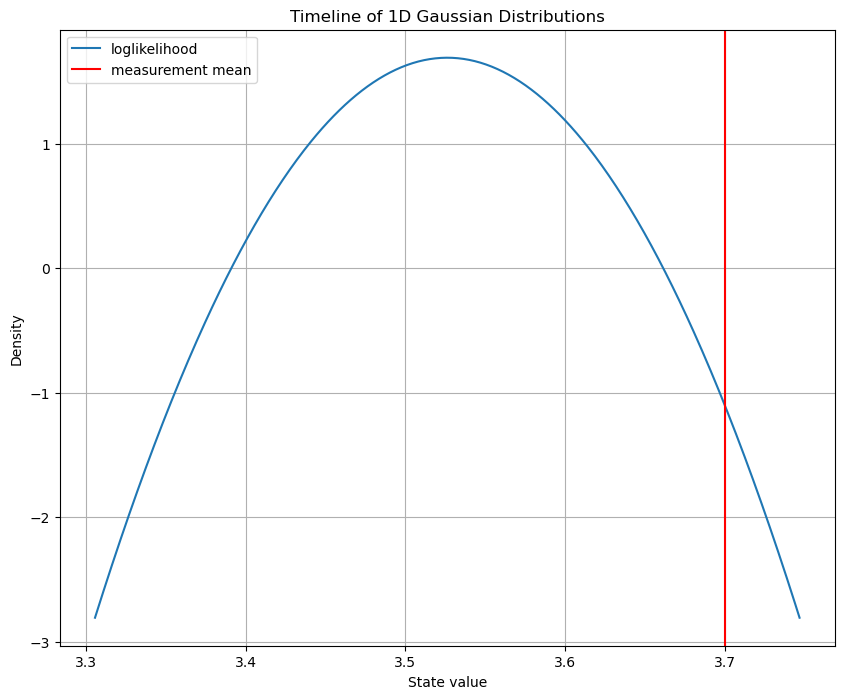

In [107]:
## visualization of the likelihood and loglikelihood at a specific step (same step as in previosu cell)
step_sigma = sigmas[step]
step_x_grid_likelihood = np.linspace(step_prior_mean - 3 * step_sigma**0.5, step_prior_mean + 3 * step_sigma**0.5, 500)
step_pdf_likelihood = (1 / np.sqrt(2*np.pi*step_sigma)) * np.exp(-(step_x_grid_likelihood - step_prior_mean)**2 / (2 * step_sigma))
plt.figure(figsize=(10, 8))
plt.plot(step_x_grid_likelihood, step_pdf_likelihood, label="likelihood")
plt.axvline(x=step_measured_mean, color='red', label="measurement mean")
plt.xlabel("State value")
plt.ylabel("Density")
plt.title("Timeline of 1D Gaussian Distributions")
plt.legend()
plt.grid(True)
plt.show()


pdf_loglikelihood = -0.5 * np.log(2 * np.pi) - 0.5 * np.log(step_sigma) - 0.5 * ((step_x_grid_likelihood - step_prior_mean) ** 2 / step_sigma)
plt.figure(figsize=(10, 8))
plt.plot(step_x_grid_likelihood, pdf_loglikelihood, label="loglikelihood")
plt.axvline(x=step_measured_mean, color='red', label="measurement mean")
plt.xlabel("State value")
plt.ylabel("Density")
plt.title("Timeline of 1D Gaussian Distributions")
plt.legend()
plt.grid(True)
plt.show()

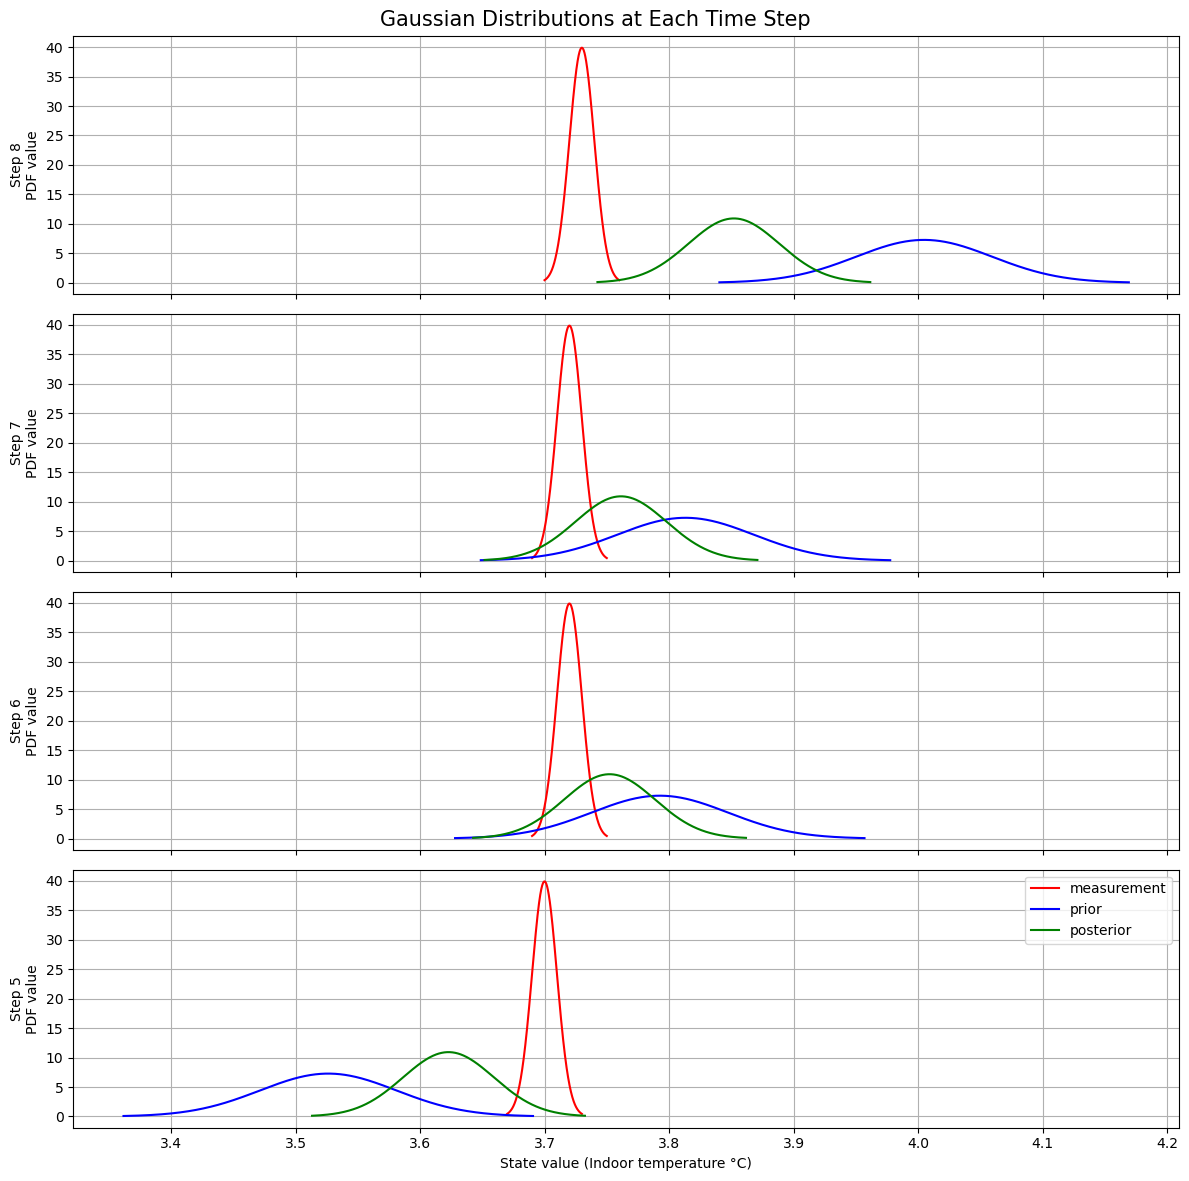

In [108]:
steps_to_plot = [5, 6, 7, 8]

color_meas = "red"
color_pred = "blue"
color_upd  = "green"

fig, axes = plt.subplots(len(steps_to_plot), 1, figsize=(12, 12),
                         sharex=True)   # same x-axis

# Reverse axes so first step is at the bottom
axes = axes[::-1]

for ax, step in zip(axes, steps_to_plot):

    # ==== MEASUREMENT ====
    measured_mean = Tint[step]
    measured_var = r**2
    xm = np.linspace(measured_mean - 3*np.sqrt(measured_var),
                     measured_mean + 3*np.sqrt(measured_var), 500)
    pdf_meas = (1/np.sqrt(2*np.pi*measured_var)) * \
               np.exp(-(xm - measured_mean)**2/(2*measured_var))

    # ==== PRIOR ====
    prior_mean = x_prior[1, step]
    prior_var = P_prior[step]
    xp = np.linspace(prior_mean - 3*np.sqrt(prior_var),
                     prior_mean + 3*np.sqrt(prior_var), 500)
    pdf_prior = (1/np.sqrt(2*np.pi*prior_var)) * \
                np.exp(-(xp - prior_mean)**2/(2*prior_var))

    # ==== POSTERIOR ====
    post_mean = x_posterior[1, step]
    post_var = P_posterior[step]
    xu = np.linspace(post_mean - 3*np.sqrt(post_var),
                     post_mean + 3*np.sqrt(post_var), 500)
    pdf_post = (1/np.sqrt(2*np.pi*post_var)) * \
               np.exp(-(xu - post_mean)**2/(2*post_var))

    # ==== PLOT (true PDF values) ====
    ax.plot(xm, pdf_meas, color=color_meas, label="measurement")
    ax.plot(xp, pdf_prior, color=color_pred, label="prior")
    ax.plot(xu, pdf_post,  color=color_upd,  label="posterior")

    ax.set_ylabel(f"Step {step}\nPDF value")
    ax.grid(True)

# shared bottom label
axes[0].set_xlabel("State value (Indoor temperature °C)")

# one legend total
axes[0].legend(loc="upper right")

fig.suptitle("Gaussian Distributions at Each Time Step", fontsize=15)
plt.tight_layout()
plt.show()


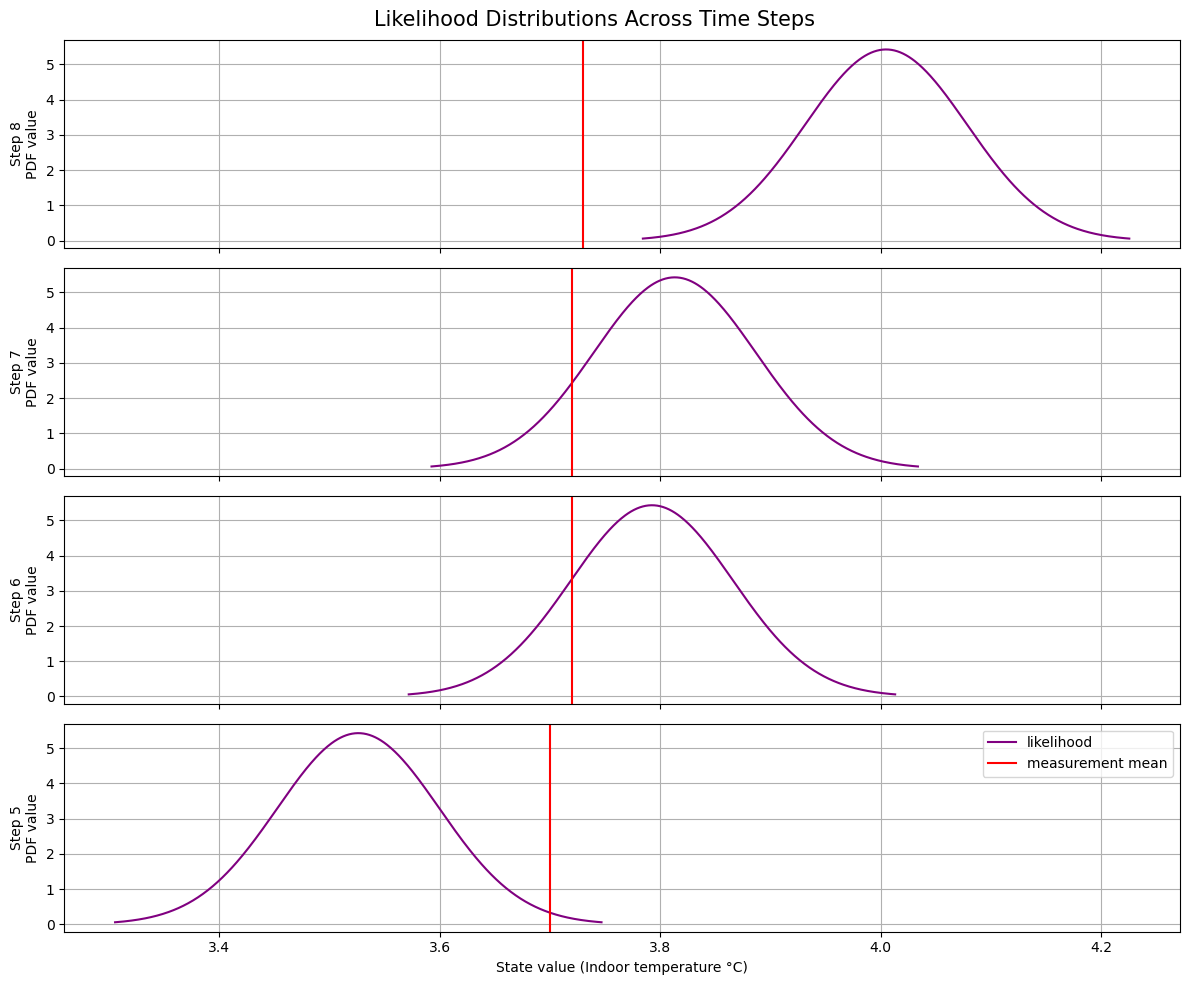

In [109]:
## Visualization of the likelihood over multiple timesteps
steps_to_plot = [5, 6, 7, 8]

color_ll = "purple"
color_meas = "red"

# Create subplots, one per step
fig, axes = plt.subplots(len(steps_to_plot), 1, figsize=(12, 10),
                         sharex=True)  # share x-axis

# Reverse axes so first step is at the bottom
axes = axes[::-1]

for ax, step in zip(axes, steps_to_plot):

    # --- LOG-LIKELIHOOD ---
    prior_mean = x_prior[1, step]
    sigma = sigmas[step]

    xl = np.linspace(prior_mean - 3*np.sqrt(sigma),
                     prior_mean + 3*np.sqrt(sigma), 500)
    pdf_likelihood = (1 / np.sqrt(2*np.pi*sigma)) * np.exp(-(xl - prior_mean)**2 / (2 * sigma))

    # --- MEASUREMENT MEAN ---
    measured_mean = Tint[step]

    # --- PLOT likelihood ---
    ax.plot(xl, pdf_likelihood, color=color_ll, label="likelihood")

    # --- MEASUREMENT vertical line ---
    ax.axvline(measured_mean, color=color_meas, label="measurement mean")

    ax.set_ylabel(f"Step {step}\nPDF value")
    ax.grid(True)

# Shared X-axis label
axes[0].set_xlabel("State value (Indoor temperature °C)")

# Only one legend
axes[0].legend(loc="upper right")

fig.suptitle("Likelihood Distributions Across Time Steps", fontsize=15)
plt.tight_layout()
plt.show()

## Conclusion

Congratulations if you made it up till here. Now you know how to implement linear kalman filter and how to compute the likelihood fuunction in complicated cases. 

With the visualizations you should be able to understand every single detail of the method steps. 

This is not the full story, it is just a step in the process of identifying these RC models. Here you have made hypothesis on the model parameters (R&C and initial conditions and the model uncertainties). These parameters however are not evident. So we need to identify them.

Thus an optimisation algorithm is to be run on top of this likelihood computation to find the parameters that maximize this likelihood.

This is the objective of the next TD.